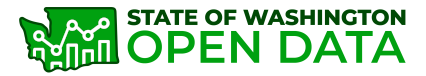

# ***Washington State EV Population Analysis — 2023–2026***

##**Problem Statement**

The adoption of electric vehicles (EVs) is growing as the transportation industry moves toward more sustainable mobility. However, understanding the distribution of EVs across manufacturers, vehicle models, model years, vehicle types, and geographic locations is essential for identifying adoption patterns and supporting informed planning and decision-making. This project aims to analyze the Electric Vehicle Population dataset for Washington State using Python to identify the most common EV manufacturers and models, examine the distribution of Battery Electric Vehicles (BEVs) and Plug-in Hybrid Electric Vehicles (PHEVs), evaluate electric driving ranges, and identify counties and cities with the highest numbers of recorded EVs. The analysis will also explore Clean Alternative Fuel Vehicle (CAFV) eligibility patterns.


##**Project Objectives**

- Analyze the distribution of registered EVs by model year.

- Identify the most popular EV manufacturers and models based on vehicle counts.

- Compare Battery Electric Vehicles (BEVs) and Plug-in Hybrid Electric Vehicles (PHEVs).

- Analyze electric range across vehicle types, manufacturers, and models.

- Identify counties and cities with the highest numbers of registered EVs.

- Examine Clean Alternative Fuel Vehicle (CAFV) eligibility patterns.

- Analyze EV records per 1,000 residents using census-tract population estimates.

- Develop an interactive Looker Studio (Data Studio) dashboard to present key findings and support data-driven insights.

##**Dataset**:

- Electric Vehicle Population Data

    Source: Washington State Open Data

    link: https://data.wa.gov/Transportation/Electric-Vehicle-Population-Data/f6w7-q2d2/about_data

- Census Population Data Population data was obtained from the 2024 American Community Survey (ACS) 5-Year Estimates published by the U.S. Census Bureau. Source: U.S. Census Bureau — American Community Survey

##**Tools and Technologies:**

- **Data Source** — Washington State Open Data
- **Python** — Data Cleaning, Exploratory Data Analysis (EDA), and Visualization
- **Pandas & NumPy** — Data Manipulation and Numerical Analysis
- **Matplotlib, Seaborn & Plotly** — Data Visualization
- **Looker Studio** — Dashboard Creation
- **Google Colab** — Python Development Environment
- **GitHub** — Version Control and Project Portfolio

##**Dataset Onboarding and Verification:**

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import os
import plotly.express as px
import requests

In [ ]:
df = pd.read_csv("Raw_Data_Electric_Vehicle_Population_Data_20261006.csv")
df.head()

,VIN (1-10),County,City,State,Postal Code,Model Year,Make,Model,Electric Vehicle Type,Clean Alternative Fuel Vehicle (CAFV) Eligibility,Electric Range,Legislative District,DOL Vehicle ID,Vehicle Location,Electric Utility,2020 GEOID
0,1N4AZ1CP3K,King,Shoreline,WA,98155.0,2019,NISSAN,LEAF,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,150.0,32.0,168526641,POINT (-122.30304 47.75494),CITY OF SEATTLE - (WA)|CITY OF TACOMA - (WA),5.303302e+10
1,WBY8P4C51K,King,Kirkland,WA,98033.0,2019,BMW,I3,Plug-in Hybrid Electric Vehicle (PHEV),Clean Alternative Fuel Vehicle Eligible,126.0,48.0,9418181,POINT (-122.2066 47.67887),PUGET SOUND ENERGY INC||CITY OF TACOMA - (WA),5.303302e+10
2,3FA6P0SU8G,Snohomish,Lynnwood,WA,98036.0,2016,FORD,FUSION,Plug-in Hybrid Electric Vehicle (PHEV),Not eligible due to low battery range,19.0,1.0,172853495,POINT (-122.29245 47.82557),PUGET SOUND ENERGY INC,5.306105e+10
3,5YJ3E1EB3N,Yakima,Wapato,WA,98951.0,2022,TESLA,MODEL 3,Battery Electric Vehicle (BEV),Eligibility unknown as battery range has not b...,0.0,15.0,204768175,POINT (-120.42083 46.44779),PACIFICORP,5.307794e+10
4,WBY1Z2C53F,King,Renton,WA,98055.0,2015,BMW,I3,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,81.0,11.0,269262920,POINT (-122.19488 47.44034),PUGET SOUND ENERGY INC||CITY OF TACOMA - (WA),5.303303e+10


In [ ]:
df.tail()

,VIN (1-10),County,City,State,Postal Code,Model Year,Make,Model,Electric Vehicle Type,Clean Alternative Fuel Vehicle (CAFV) Eligibility,Electric Range,Legislative District,DOL Vehicle ID,Vehicle Location,Electric Utility,2020 GEOID
299700,ZACPDFDW7R,Kitsap,Port Orchard,WA,98312.0,2024,DODGE,HORNET,Plug-in Hybrid Electric Vehicle (PHEV),Clean Alternative Fuel Vehicle Eligible,32.0,26.0,278485665,POINT (-122.65223 47.57192),PUGET SOUND ENERGY INC,5.303509e+10
299701,KM8KMDAF3P,Grant,Ephrata,WA,98823.0,2023,HYUNDAI,IONIQ 5,Battery Electric Vehicle (BEV),Eligibility unknown as battery range has not b...,0.0,13.0,223872596,POINT (-119.55096 47.31909),PUD NO 2 OF GRANT COUNTY,5.302501e+10
299702,1GT10BDD5S,Kitsap,Poulsbo,WA,98370.0,2025,GMC,HUMMER EV PICKUP,Battery Electric Vehicle (BEV),Eligibility unknown as battery range has not b...,0.0,23.0,280685807,POINT (-122.64681 47.73689),PUGET SOUND ENERGY INC,5.303509e+10
299703,5YJ3E1EB8N,Snohomish,Everett,WA,98208.0,2022,TESLA,MODEL 3,Battery Electric Vehicle (BEV),Eligibility unknown as battery range has not b...,0.0,44.0,214860208,POINT (-122.22478 47.91564),PUGET SOUND ENERGY INC,5.306104e+10
299704,JM3KKCHA9T,King,Duvall,WA,98019.0,2026,MAZDA,CX-90,Plug-in Hybrid Electric Vehicle (PHEV),Not eligible due to low battery range,27.0,45.0,292954399,POINT (-121.98609 47.74068),PUGET SOUND ENERGY INC||CITY OF TACOMA - (WA),5.303303e+10


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 299705 entries, 0 to 299704
Data columns (total 16 columns):
 #   Column                                             Non-Null Count   Dtype  
---  ------                                             --------------   -----  
 0   VIN (1-10)                                         299705 non-null  object 
 1   County                                             299694 non-null  object 
 2   City                                               299694 non-null  object 
 3   State                                              299705 non-null  object 
 4   Postal Code                                        299694 non-null  float64
 5   Model Year                                         299705 non-null  int64  
 6   Make                                               299705 non-null  object 
 7   Model                                              299705 non-null  object 
 8   Electric Vehicle Type                              299705 non-null  object

In [ ]:
df.describe()

,Postal Code,Model Year,Electric Range,Legislative District,DOL Vehicle ID,2020 GEOID
count,299694.000000,299705.000000,299679.000000,298915.000000,2.997050e+05,2.996940e+05
mean,98176.001962,2022.344666,36.663313,28.754589,2.509924e+08,5.296742e+10
std,2652.053836,3.093007,76.034423,14.892388,6.238702e+07,1.687605e+09
min,1030.000000,1999.000000,0.000000,1.000000,4.469000e+03,1.001020e+09
25%,98052.000000,2021.000000,0.000000,17.000000,2.283017e+08,5.303301e+10
50%,98134.000000,2023.000000,0.000000,32.000000,2.679271e+08,5.303303e+10
75%,98391.000000,2024.000000,32.000000,42.000000,2.845359e+08,5.305394e+10
max,99801.000000,2027.000000,337.000000,49.000000,4.791150e+08,6.601095e+10


In [ ]:
df.shape

(299705, 16)

In [ ]:
df.columns.tolist()

['VIN (1-10)',
 'County',
 'City',
 'State',
 'Postal Code',
 'Model Year',
 'Make',
 'Model',
 'Electric Vehicle Type',
 'Clean Alternative Fuel Vehicle (CAFV) Eligibility',
 'Electric Range',
 'Legislative District',
 'DOL Vehicle ID',
 'Vehicle Location',
 'Electric Utility',
 '2020 GEOID']

In [ ]:
df.isnull().sum()

,0
VIN (1-10),0
County,11
City,11
State,0
Postal Code,11
Model Year,0
Make,0
Model,0
Electric Vehicle Type,0
Clean Alternative Fuel Vehicle (CAFV) Eligibility,0


In [ ]:
(df.isnull().sum() / len(df)*100).sort_values(ascending=False)

,0
Legislative District,0.263593
Electric Range,0.008675
Vehicle Location,0.006673
County,0.003670
Electric Utility,0.003670
City,0.003670
Postal Code,0.003670
2020 GEOID,0.003670
Model,0.000000
Make,0.000000


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df['State'].unique()

array(['WA', 'CA', 'BC', 'NV', 'MI', 'OR', 'MD', 'MN', 'IL', 'VA', 'MO',
       'FL', 'NC', 'DC', 'TX', 'ME', 'AR', 'CO', 'ID', 'GA', 'NY', 'PA',
       'SD', 'WY', 'CT', 'KS', 'AL', 'KY', 'AZ', 'SC', 'OH', 'WI', 'TN',
       'MS', 'NE', 'NH', 'AE', 'NJ', 'MA', 'RI', 'IN', 'LA', 'HI', 'GU',
       'NM', 'UT', 'IA', 'MT', 'DE', 'AK'], dtype=object)

##**Data Transformation & Formatting**

In [ ]:
df_WA = df[df['State']=='WA'].copy()   # Created a new dataset "df_WA" using dataframe as I need only Washington State data from the original dataset.

In [ ]:
df_WA.shape

(298916, 16)

In [ ]:
df_WA['State'].unique()

array(['WA'], dtype=object)

In [ ]:
df_WA.info()

<class 'pandas.core.frame.DataFrame'>
Index: 298916 entries, 0 to 299704
Data columns (total 16 columns):
 #   Column                                             Non-Null Count   Dtype  
---  ------                                             --------------   -----  
 0   VIN (1-10)                                         298916 non-null  object 
 1   County                                             298916 non-null  object 
 2   City                                               298916 non-null  object 
 3   State                                              298916 non-null  object 
 4   Postal Code                                        298916 non-null  float64
 5   Model Year                                         298916 non-null  int64  
 6   Make                                               298916 non-null  object 
 7   Model                                              298916 non-null  object 
 8   Electric Vehicle Type                              298916 non-null  object 
 9 

In [ ]:
df_WA.describe()

,Postal Code,Model Year,Electric Range,Legislative District,DOL Vehicle ID,2020 GEOID
count,298916.000000,298916.000000,298890.000000,298915.000000,2.989160e+05,2.989160e+05
mean,98281.387169,2022.345870,36.660243,28.754589,2.510107e+08,5.304024e+10
std,320.334637,3.093442,76.027276,14.892388,6.239416e+07,1.681106e+07
min,98001.000000,1999.000000,0.000000,1.000000,4.469000e+03,5.300195e+10
25%,98052.000000,2021.000000,0.000000,17.000000,2.283169e+08,5.303301e+10
50%,98134.000000,2023.000000,0.000000,32.000000,2.679498e+08,5.303303e+10
75%,98391.000000,2024.000000,32.000000,42.000000,2.845567e+08,5.305394e+10
max,99403.000000,2027.000000,337.000000,49.000000,4.791150e+08,5.307794e+10


In [ ]:
df_WA.isnull().sum()

,0
VIN (1-10),0
County,0
City,0
State,0
Postal Code,0
Model Year,0
Make,0
Model,0
Electric Vehicle Type,0
Clean Alternative Fuel Vehicle (CAFV) Eligibility,0


In [ ]:
(df_WA.isnull().sum()/len(df_WA)*100)

,0
VIN (1-10),0.000000
County,0.000000
City,0.000000
State,0.000000
Postal Code,0.000000
Model Year,0.000000
Make,0.000000
Model,0.000000
Electric Vehicle Type,0.000000
Clean Alternative Fuel Vehicle (CAFV) Eligibility,0.000000


In [ ]:
df_WA['Electric Range'] = df_WA['Electric Range'].fillna(df_WA.groupby('Clean Alternative Fuel Vehicle (CAFV) Eligibility')['Electric Range'].transform(lambda x: x.mode()[0] if not x.mode().empty else 0))

In [ ]:
df_WA['Legislative District'] = df_WA['Legislative District'].fillna(df_WA.groupby('Postal Code')['Legislative District'].transform(lambda x: x.mode()[0] if not x.mode().empty else None))

In [ ]:
df_WA['Vehicle Location'] = df_WA['Vehicle Location'].fillna(df_WA.groupby('City')['Vehicle Location'].transform(lambda x: x.mode()[0] if not x.mode().empty else "Unknown"))

In [ ]:
(df_WA.isnull().sum()/len(df_WA)*100)

,0
VIN (1-10),0.0
County,0.0
City,0.0
State,0.0
Postal Code,0.0
Model Year,0.0
Make,0.0
Model,0.0
Electric Vehicle Type,0.0
Clean Alternative Fuel Vehicle (CAFV) Eligibility,0.0


In [ ]:
# Change the datatypes
df_WA[df_WA.select_dtypes(include='object').columns] = df_WA.select_dtypes(include='object').astype('string')
df_WA[['Postal Code','Legislative District','DOL Vehicle ID','2020 GEOID']] = df_WA[['Postal Code','Legislative District','DOL Vehicle ID','2020 GEOID']].astype('string')
df_WA['Electric Range'] = df_WA['Electric Range'].astype('int64')

# Extract longitude and latitude in new columns
coords = df_WA['Vehicle Location'].str.extract(r'POINT\s*\(\s*(-?\d+\.?\d*)\s+(-?\d+\.?\d*)\s*\)')
df_WA['Longitude'] = coords[0].astype('float64')
df_WA['Latitude'] = coords[1].astype('float64')

print(df_WA[['Longitude', 'Latitude']].dtypes)
print(df_WA[['Longitude', 'Latitude']].head())

Longitude    float64
Latitude     float64
dtype: object
   Longitude  Latitude
0 -122.30304  47.75494
1 -122.20660  47.67887
2 -122.29245  47.82557
3 -120.42083  46.44779
4 -122.19488  47.44034


In [ ]:
df_WA['GEOID'] = (df_WA['2020 GEOID'].str.replace(r'\.0$', '', regex=True).str.zfill(11))   # Extract GEOID in new column without decimal points.

In [ ]:
print(df_WA[['2020 GEOID', 'GEOID']].head(10))
print("Unique cleaned GEOIDs:", df_WA['GEOID'].nunique())
print("Missing cleaned GEOIDs:", df_WA['GEOID'].isna().sum())
df_WA.info()

      2020 GEOID        GEOID
0  53033020500.0  53033020500
1  53033022703.0  53033022703
2  53061051932.0  53061051932
3  53077940008.0  53077940008
4  53033025805.0  53033025805
5  53029971302.0  53029971302
6  53061052207.0  53061052207
7  53067011822.0  53067011822
8  53077000100.0  53077000100
9  53035091302.0  53035091302
Unique cleaned GEOIDs: 1770
Missing cleaned GEOIDs: 0
<class 'pandas.core.frame.DataFrame'>
Index: 298916 entries, 0 to 299704
Data columns (total 19 columns):
 #   Column                                             Non-Null Count   Dtype  
---  ------                                             --------------   -----  
 0   VIN (1-10)                                         298916 non-null  string 
 1   County                                             298916 non-null  string 
 2   City                                               298916 non-null  string 
 3   State                                              298916 non-null  string 
 4   Postal Code        

In [ ]:
df_WA.duplicated().sum()

np.int64(0)

In [ ]:
df_WA['DOL Vehicle ID'].duplicated().sum()

np.int64(0)

In [ ]:
df_WA.shape # Check the dataset dimensions

(298916, 19)

In [ ]:
df_WA.info() # Review the data types

<class 'pandas.core.frame.DataFrame'>
Index: 298916 entries, 0 to 299704
Data columns (total 19 columns):
 #   Column                                             Non-Null Count   Dtype  
---  ------                                             --------------   -----  
 0   VIN (1-10)                                         298916 non-null  string 
 1   County                                             298916 non-null  string 
 2   City                                               298916 non-null  string 
 3   State                                              298916 non-null  string 
 4   Postal Code                                        298916 non-null  string 
 5   Model Year                                         298916 non-null  int64  
 6   Make                                               298916 non-null  string 
 7   Model                                              298916 non-null  string 
 8   Electric Vehicle Type                              298916 non-null  string 
 9 

##**Finding Outliers and analyse them:**

In [ ]:
df_WA.describe(include = "string") # Get summary statistics

,VIN (1-10),County,City,State,Postal Code,Make,Model,Electric Vehicle Type,Clean Alternative Fuel Vehicle (CAFV) Eligibility,Legislative District,DOL Vehicle ID,Vehicle Location,Electric Utility,2020 GEOID,GEOID
count,298916,298916,298916,298916,298916,298916,298916,298916,298916,298916,298916,298916,298916,298916,298916
unique,18364,39,507,1,590,51,202,2,3,49,298916,589,76,1770,1770
top,7SAYGDEE7P,King,Seattle,WA,98052.0,TESLA,MODEL Y,Battery Electric Vehicle (BEV),Eligibility unknown as battery range has not b...,41.0,269262920,POINT (-122.13158 47.67858),PUGET SOUND ENERGY INC||CITY OF TACOMA - (WA),53033009300.0,53033009300
freq,1225,144257,45469,298916,7155,122573,66342,241125,195748,17969,1,7155,103988,1486,1486


In [ ]:
df_WA.describe() # Get summary statistics

,Model Year,Electric Range,Longitude,Latitude
count,298916.000000,298916.000000,298916.000000,298916.000000
mean,2022.345870,36.675755,-122.041279,47.448921
std,3.093442,76.042160,1.091792,0.636181
min,1999.000000,0.000000,-124.627550,45.579230
25%,2021.000000,0.000000,-122.401770,47.318030
50%,2023.000000,0.000000,-122.280830,47.610010
75%,2024.000000,32.000000,-122.131580,47.736890
max,2027.000000,337.000000,-117.043980,48.999760


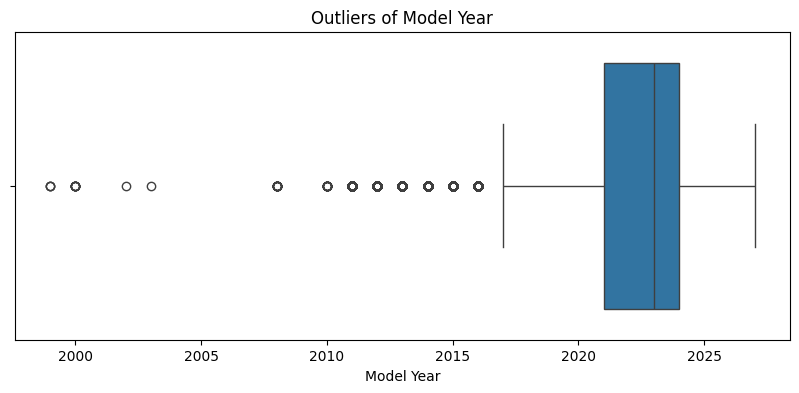

In [ ]:
plt.figure(figsize=(10, 4))
sns.boxplot(x=df_WA['Model Year'])
plt.title('Outliers of Model Year')
plt.xlabel('Model Year')
plt.show()

In [ ]:
Q1 = df_WA['Model Year'].quantile(0.25)
Q3 = df_WA['Model Year'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers_range = df_WA[(df_WA['Model Year'] < lower_limit) | (df_WA['Model Year'] > upper_limit)]


print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)
print("Potential outlier count:", len(outliers_range))
print(outliers_range['Model Year'].value_counts().sort_index())

Q1: 2021.0
Q3: 2024.0
IQR: 3.0
Lower limit: 2016.5
Upper limit: 2028.5
Potential outlier count: 18234
Model Year
1999       3
2000       8
2002       1
2003       1
2008      17
2010      18
2011     528
2012    1285
2013    3844
2014    3141
2015    4368
2016    5020
Name: count, dtype: int64


**Conclusion about the outliers in the Model Year:**

The source documentation " https://data.wa.gov/Transportation/Electric-Vehicle-Population-Data/f6w7-q2d2/about_data " states that model year is provided as text and determined by decoding the Vehicle Identification Number (VIN). The IQR method flagged 18,234 records with model years from 1999 to 2016 as potential outliers. However, these values may represent valid older electric vehicles rather than incorrect data. Therefore, **the records were retained for analysis** because no evidence of data-entry errors was established.

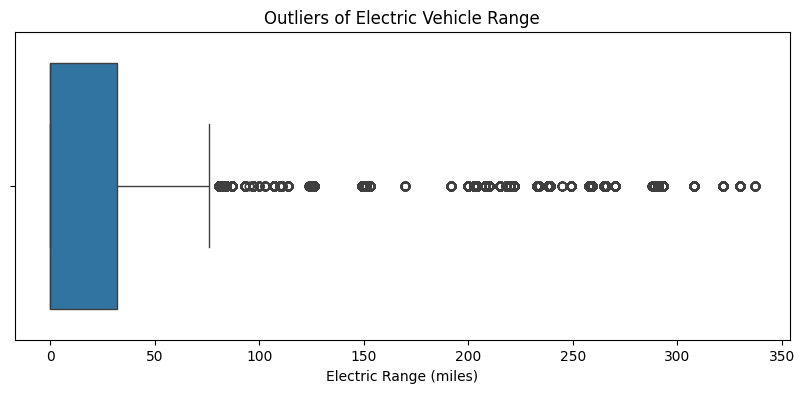

In [ ]:
plt.figure(figsize=(10, 4))
sns.boxplot(x=df_WA['Electric Range'])
plt.title('Outliers of Electric Vehicle Range')
plt.xlabel('Electric Range (miles)')
plt.show()

In [ ]:
# Investigating the outliers in Electric Range using IQR method
Q1 = df_WA['Electric Range'].quantile(0.25)
Q3 = df_WA['Electric Range'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR
outliers_range = df_WA[(df_WA['Electric Range'] < lower_limit) | (df_WA['Electric Range'] > upper_limit)]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)
print("Potential outlier count:", len(outliers_range))

Q1: 0.0
Q3: 32.0
IQR: 32.0
Lower limit: -48.0
Upper limit: 80.0
Potential outlier count: 43114


In [ ]:
# investigate the electric ranges have zero and by their vehicle types:
zero_range_count = df_WA[df_WA['Electric Range'] == 0]
print(zero_range_count['Electric Vehicle Type'].value_counts())

Electric Vehicle Type
Battery Electric Vehicle (BEV)            195745
Plug-in Hybrid Electric Vehicle (PHEV)         3
Name: count, dtype: Int64


In [ ]:
# Check which manufacturers have zero electric range

print("\nManufacturers with zero-range EVs:")
print(zero_range_count['Make'].value_counts())


Manufacturers with zero-range EVs:
Make
TESLA                     98417
FORD                      12007
HYUNDAI                   10607
CHEVROLET                 10329
RIVIAN                     9800
KIA                        8920
VOLKSWAGEN                 6851
NISSAN                     6553
BMW                        4916
SUBARU                     3256
AUDI                       3245
TOYOTA                     3137
VOLVO                      2877
CADILLAC                   2793
HONDA                      2388
MERCEDES-BENZ              2125
POLESTAR                   1491
PORSCHE                    1063
LUCID                       915
MINI                        908
LEXUS                       889
GMC                         621
GENESIS                     555
ACURA                       358
JEEP                        188
FIAT                        124
DODGE                       114
FISKER                      111
BRIGHTDROP                   61
JAGUAR                       46

In [ ]:
# Check which model years have zero electric range
print(zero_range_count['Model Year'].value_counts().sort_index())

Model Year
2008        1
2015        1
2018        1
2019        5
2020       71
2021    15699
2022    25152
2023    54036
2024    38590
2025    29456
2026    32191
2027      545
Name: count, dtype: int64


In [ ]:
# Check zero electric range with respect to CAFV Eligibility:
print(zero_range_count['Clean Alternative Fuel Vehicle (CAFV) Eligibility'].value_counts().sort_index())

Clean Alternative Fuel Vehicle (CAFV) Eligibility
Eligibility unknown as battery range has not been researched    195748
Name: count, dtype: Int64


**Conclusion about Outliers in Electric Range:**

A substantial proportion of Battery Electric Vehicle records in the Washington State EV dataset have an electric range recorded as zero. These records occur across numerous manufacturers and are concentrated in recent model years, particularly 2023. Also All records with zero electric range were found to have a **CAFV eligibility** status of **“Eligibility unknown as battery range has not been researched.”** This investigation shows whether zero values represent missing or unreported information. Zero electric range values were treated as potentially missing or unavailable range.

In [ ]:
# Keep records with a positive electric range for future analysis in Electric ranges.
df_WA_range = df_WA[df_WA['Electric Range'] > 0].copy()
print(df_WA_range.shape)
print(df_WA_range['Electric Range'].describe())

(103168, 19)
count    103168.000000
mean        106.263279
std          96.743088
min           1.000000
25%          30.000000
50%          47.000000
75%         215.000000
max         337.000000
Name: Electric Range, dtype: float64


In [ ]:
Q1 = df_WA_range['Electric Range'].quantile(0.25)
Q3 = df_WA_range['Electric Range'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR
outliers_range = df_WA_range[(df_WA_range['Electric Range'] < lower_limit) | (df_WA_range['Electric Range'] > upper_limit)]

print("IQR:", IQR)
print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)
print("Potential outlier count:", len(outliers_range))

IQR: 185.0
Lower limit: -247.5
Upper limit: 492.5
Potential outlier count: 0


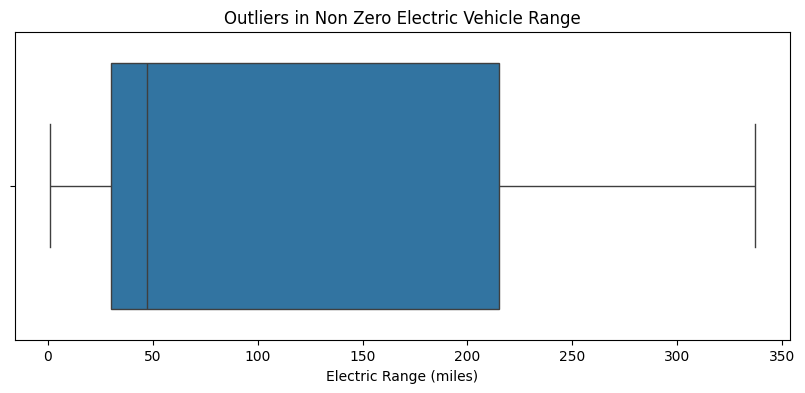

In [ ]:
plt.figure(figsize=(10,4))
sns.boxplot(x=df_WA_range['Electric Range'])
plt.title('Outliers in Non Zero Electric Vehicle Range')
plt.xlabel('Electric Range (miles)')
plt.show()

**Outlier Analysis and Data Handling**
- **Model Year:** The IQR method identified 18,234 potential outliers from 1999 to 2016. These records were retained because older model years may represent valid electric vehicles.
- **Electric Range — Zero Values:** A total of 195,748 records had zero electric range. All were classified as “Eligibility unknown as battery range has not been researched” under CAFV eligibility, suggesting that range information may
be unavailable or unresearched.
- **Handling Zero Values:** Zero-range records were excluded from electric-range comparisons but retained in the original dataset for EV population analysis.
- **Electric Range — Positive Values:** The IQR was 185 miles, with lower and upper limits of −247.5 and 492.5 miles. No potential outliers were identified among the 103,168 positive-range records.
- **Final Decision:** No records were removed solely because of statistical outlier detection. This preserves potentially valid vehicle records and supports more reliable analysis.

##**Download the Cleaned Dataset**

In [ ]:
df_WA.to_csv("Washington_State_EV_Cleaned.csv",index=False)
from google.colab import files
files.download("Washington_State_EV_Cleaned.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

##**Exploratory Data Analysis (EDA) and Visualization:**

In [ ]:
# 1. Which model years have the most registered EVs?
# Understand how the EV population varies by model year.

# 2. Which manufacturers dominate the EV population?
# Identify the most common vehicle makes.

# 3. Which EV types have the highest electric range?
# Compare Battery Electric Vehicles (BEVs) and Plug-in Hybrid Electric Vehicles (PHEVs).

# 4. Which counties or cities have the most EVs?
# Explore geographic distribution using the location columns available in the dataset.

# 5. What is the proportion of BEVs and PHEVs in the dataset?
# Understand the composition of the recorded EV population.

# 6. What is the distribution of Clean Alternative Fuel Vehicle (CAFV) eligibility?
# Determine how many records fall into eligible, ineligible, and unknown categories.

# 7. Which electric utilities serve areas with the most recorded EVs?
# Compare the EV records associated with different utility service areas.

# 8. Which manufacturers are represented across model years?
# understand which EV manufacturers have the highest number of records across different model years

# 9. EV registrations vs. population
# Join tract-level EV counts to Census population data to calculate EV registrations per 1,000 residents.

In [ ]:
ev_by_year = (df_WA.groupby('Model Year').size().sort_index())
print(ev_by_year)

Model Year
1999        3
2000        8
2002        1
2003        1
2008       17
2010       18
2011      528
2012     1285
2013     3844
2014     3141
2015     4368
2016     5020
2017     8410
2018    13942
2019    10795
2020    12156
2021    20791
2022    30160
2023    61425
2024    49273
2025    36938
2026    36237
2027      555
dtype: int64


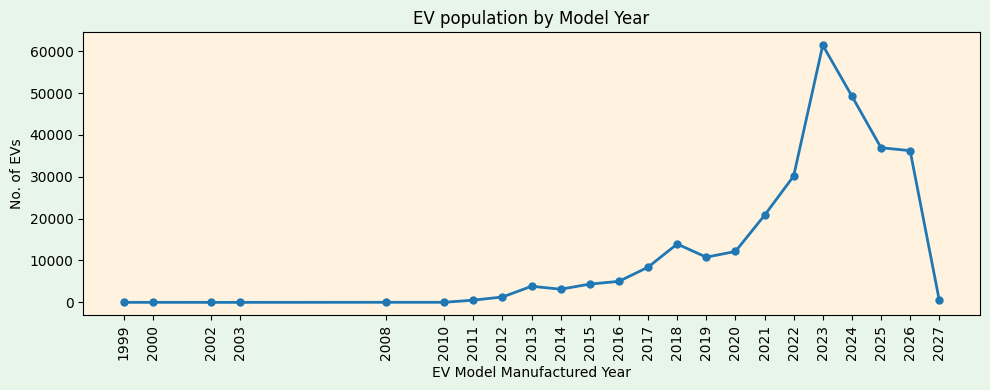

In [ ]:
top_10_Model_Years = ev_by_year.sort_values(ascending=False).head(10)
plt.figure(figsize = (10,4), facecolor= '#E8F5E9')
plt.gca().set_facecolor('#FFF3E0')
plt.plot(ev_by_year.index, ev_by_year.values, marker = 'o', linestyle='-', linewidth=2, markersize=5)
plt.title("EV population by Model Year")
plt.xlabel("EV Model Manufactured Year")
plt.ylabel("No. of EVs")
plt.xticks(ev_by_year.index, rotation = 90)
plt.tight_layout()
plt.show()

Key findings
- 2023 ranks first, with 61,425 EV records, making it the most represented model year in the dataset.
- 2024 ranks second, with 49,273 records, approximately 19.8% fewer than 2023.
- The 2025 and 2026 model years have 36,938 and 36,237 records, respectively, showing similar representation.
- The number of records generally increases across earlier model years toward 2023, although the pattern is not perfectly consistent.
- Model years 2021–2026 account for a substantial portion of the records in top 10, indicating strong representation of relatively recent model years.

Important observation: The 2026 model year may be incomplete because the dataset was collected before the model year had fully elapsed. These counts represent vehicles recorded in the dataset, not necessarily annual sales or registrations completed during each calendar year.

In [ ]:
ev_by_make = (df_WA.groupby('Make').size().sort_values(ascending=False))
print(ev_by_make.head(10))

Make
TESLA        122573
CHEVROLET     20195
FORD          16075
NISSAN        16022
KIA           14756
TOYOTA        13962
HYUNDAI       12334
BMW           12327
RIVIAN         9800
VOLVO          8171
dtype: int64


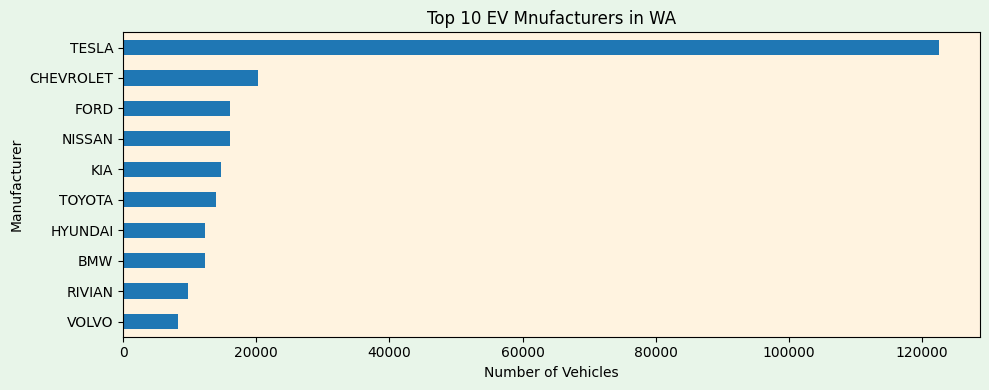

In [ ]:
plt.figure(figsize = (10,4), facecolor= '#E8F5E9')
plt.gca().set_facecolor('#FFF3E0')
top_10_EV_Make = ev_by_make.head(10)
top_10_EV_Make.sort_values().plot(kind='barh')
plt.title('Top 10 EV Mnufacturers in WA')
plt.xlabel('Number of Vehicles')
plt.ylabel('Manufacturer')
plt.tight_layout()
plt.show()

Key findings
- Tesla dominates the dataset, with 122,573 recorded vehicles.
- Chevrolet ranks second with 20,195 vehicles.
- Tesla has approximately 6.1 times as many records as Chevrolet.
- Ford and Nissan have very similar counts, differing by only 53 vehicles.
- Hyundai and BMW also have nearly identical counts, differing by just 7 vehicles.

Tesla's share of the top 10 manufacturers 46.3%.
Tesla accounts for approximately 46.3% of the combined vehicle records among these ten manufacturers.

In [ ]:
range_data = df_WA[df_WA['Electric Range'] > 0]
range_comparison = (range_data.groupby('Electric Vehicle Type')['Electric Range'].agg(['count', 'mean', 'median', 'min', 'max']).round(2))
print(range_comparison)

                                        count    mean  median  min  max
Electric Vehicle Type                                                  
Battery Electric Vehicle (BEV)          45380  200.46   215.0   29  337
Plug-in Hybrid Electric Vehicle (PHEV)  57788   32.29    32.0    1  215


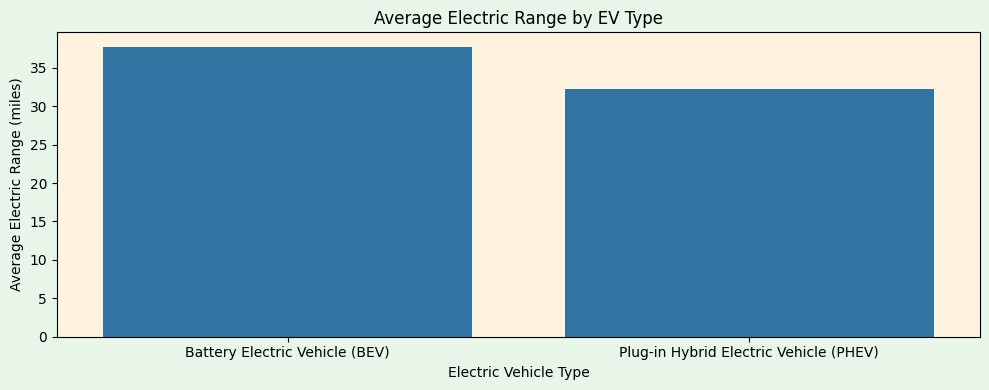

In [ ]:
plt.figure(figsize = (10,4), facecolor= '#E8F5E9')
plt.gca().set_facecolor('#FFF3E0')
sns.barplot(
    data=df_WA,
    x='Electric Vehicle Type',
    y='Electric Range',
    estimator='mean',
    errorbar=None
)
plt.title('Average Electric Range by EV Type')
plt.xlabel('Electric Vehicle Type')
plt.ylabel('Average Electric Range (miles)')
plt.tight_layout()
plt.show()

Key findings
- BEVs have a much higher average electric range of 200.46 miles compared with 32.29 miles for PHEVs.
- BEVs have a median range of 215 miles, while PHEVs have a median range of 32 miles.
- BEVs have the highest maximum electric range at 337 miles, compared with 215 miles for PHEVs.
- The analysis includes 45,380 BEV records and 57,788 PHEV records with positive electric-range values.

Overall, BEVs offer a substantially higher recorded electric range than PHEVs when zero-range values are excluded.

In [ ]:
county_counts = (df_WA['County'].value_counts())
print(county_counts)

County
King            144257
Snohomish        37818
Pierce           25042
Clark            18782
Thurston         10985
Kitsap           10351
Spokane           8741
Whatcom           7560
Benton            4505
Skagit            3570
Island            3289
Yakima            2200
Chelan            2022
Clallam           1892
Cowlitz           1678
Jefferson         1655
Mason             1602
Lewis             1423
San Juan          1381
Franklin          1358
Grant             1265
Kittitas          1220
Grays Harbor      1187
Walla Walla        874
Douglas            704
Whitman            632
Klickitat          572
Okanogan           491
Stevens            430
Pacific            398
Skamania           320
Adams              143
Asotin             135
Pend Oreille       132
Wahkiakum          105
Lincoln             99
Ferry               65
Columbia            25
Garfield             8
Name: count, dtype: Int64


Key findings

- King County leads significantly, with 144,257 recorded EVs, making it the county with the highest EV population in the dataset.
- Snohomish County ranks second with 37,818 EVs, followed by Pierce County with 25,042.
- Clark County ranks fourth with 18,782 EVs, while Thurston County ranks fifth with 10,985.
- EV records are concentrated in a few counties, particularly King, Snohomish, and Pierce.
- Garfield County has the fewest recorded EVs, with only 8, indicating substantial variation in EV distribution across Washington counties.

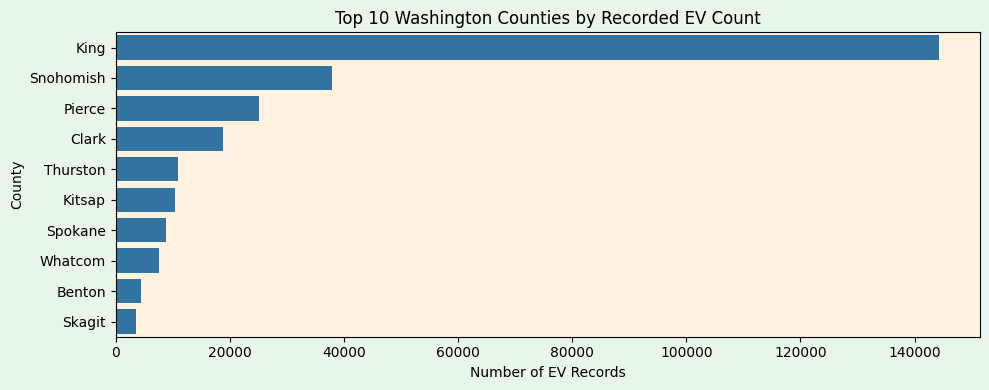

In [ ]:
plt.figure(figsize = (10,4), facecolor= '#E8F5E9')
plt.gca().set_facecolor('#FFF3E0')
sns.barplot(
    x=county_counts.head(10).values,
    y=county_counts.head(10).index
)
plt.title('Top 10 Washington Counties by Recorded EV Count')
plt.xlabel('Number of EV Records')
plt.ylabel('County')
plt.tight_layout()
plt.show()


In [ ]:
city_counts = (df_WA['City'].value_counts())
print(city_counts)

City
Seattle        45469
Bellevue       14383
Vancouver      11215
Redmond        10135
Bothell         9819
               ...  
Ryderwood          1
Matlock            1
Deer Harbor        1
Humptulips         1
Nemah              1
Name: count, Length: 507, dtype: Int64


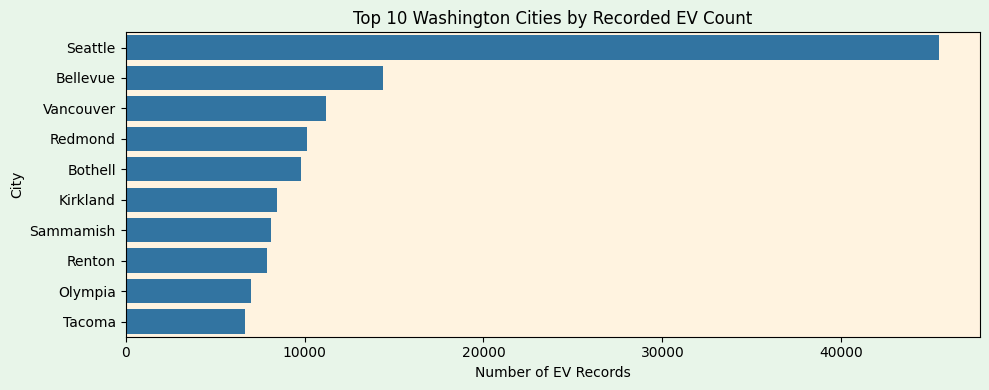

In [ ]:
plt.figure(figsize = (10,4), facecolor= '#E8F5E9')
plt.gca().set_facecolor('#FFF3E0')
sns.barplot(
    x=city_counts.head(10).values,
    y=city_counts.head(10).index
)
plt.title('Top 10 Washington Cities by Recorded EV Count')
plt.xlabel('Number of EV Records')
plt.ylabel('City')
plt.tight_layout()
plt.show()

Key findings

- Seattle has the highest recorded EV count, with 45,469 vehicles.
- Bellevue ranks second with 14,383 EVs, followed by Vancouver with 11,215.
- Redmond ranks fourth with 10,135 EVs, while Bothell ranks fifth with 9,819.
- The dataset includes EV records across 507 cities, showing a wide geographic distribution throughout Washington State.
- Several smaller communities, including Ryderwood, Matlock, and Deer Harbor, have only one recorded EV each, highlighting differences in EV distribution across cities.

In [ ]:
county_counts = (
    df_WA.groupby('County')
    .size()
    .reset_index(name='EV Count')
)

# Download US county boundary data
url = (
    "https://raw.githubusercontent.com/plotly/datasets/"
    "master/geojson-counties-fips.json"
)

geojson = requests.get(url, timeout=30).json()

# Keep Washington State counties only (state FIPS = 53)
wa_features = [
    feature for feature in geojson['features']
    if feature['properties']['STATE'] == '53'
]

wa_geojson = {
    'type': 'FeatureCollection',
    'features': wa_features
}

# Create the county map
fig = px.choropleth(
    county_counts,
    geojson=wa_geojson,
    locations='County',
    featureidkey='properties.NAME',
    color='EV Count',
    color_continuous_scale='YlOrRd',
    scope='usa',
    labels={'EV Count': 'EV Records'},
    title='Recorded EV Distribution by County in Washington State'
)

fig.update_geos(
    fitbounds='locations',
    visible=False
)

fig.update_layout(
    paper_bgcolor='#E8F5E9',
    margin={'r': 10, 't': 30, 'l': 10, 'b': 10}
)

fig.show()


In [ ]:
ev_type_total = df_WA['Electric Vehicle Type'].value_counts()
ev_type_percentage = (df_WA['Electric Vehicle Type'].value_counts(normalize = True) * 100).round(2)
ev_type_summary = pd.DataFrame({'Count': ev_type_total, 'Percentage': ev_type_percentage})
print(ev_type_summary)

                                         Count  Percentage
Electric Vehicle Type                                     
Battery Electric Vehicle (BEV)          241125       80.67
Plug-in Hybrid Electric Vehicle (PHEV)   57791       19.33


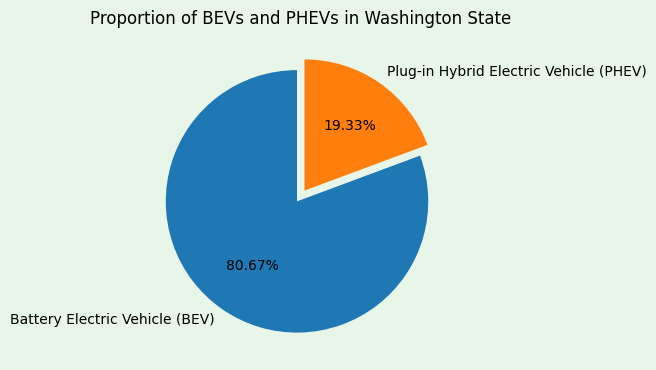

In [ ]:
plt.figure(figsize=(6, 6), facecolor= '#E8F5E9')
explode = [0.05] * len(ev_type_total)
plt.pie(
    ev_type_total,
    labels=ev_type_total.index,
    autopct='%1.2f%%',
    startangle=90,
    explode= explode
)

plt.title('Proportion of BEVs and PHEVs in Washington State')
plt.tight_layout()
plt.show()

**Key findings**
- BEVs: 241,125 records, approximately 80.68% of the dataset.
- PHEVs: 57,791 records, approximately 19.32% of the dataset.
- BEVs dominate: The dataset contains roughly 4.17 BEV records for every PHEV record.
- Overall composition: About four-fifths of the recorded EV population consists of BEVs, while approximately one-fifth consists of PHEVs.

In [ ]:
cafv_total = df_WA['Clean Alternative Fuel Vehicle (CAFV) Eligibility'].value_counts()
cafv_percentage = (df_WA['Clean Alternative Fuel Vehicle (CAFV) Eligibility'].value_counts(normalize = True)*100).round(2)
cafv_summary = pd.DataFrame({'Count': cafv_total, 'Percentage': cafv_percentage})
cafv_summary.index.name = 'CAFV Eligibility'
print(cafv_summary)

                                                     Count  Percentage
CAFV Eligibility                                                      
Eligibility unknown as battery range has not be...  195748       65.49
Clean Alternative Fuel Vehicle Eligible              79099       26.46
Not eligible due to low battery range                24069        8.05


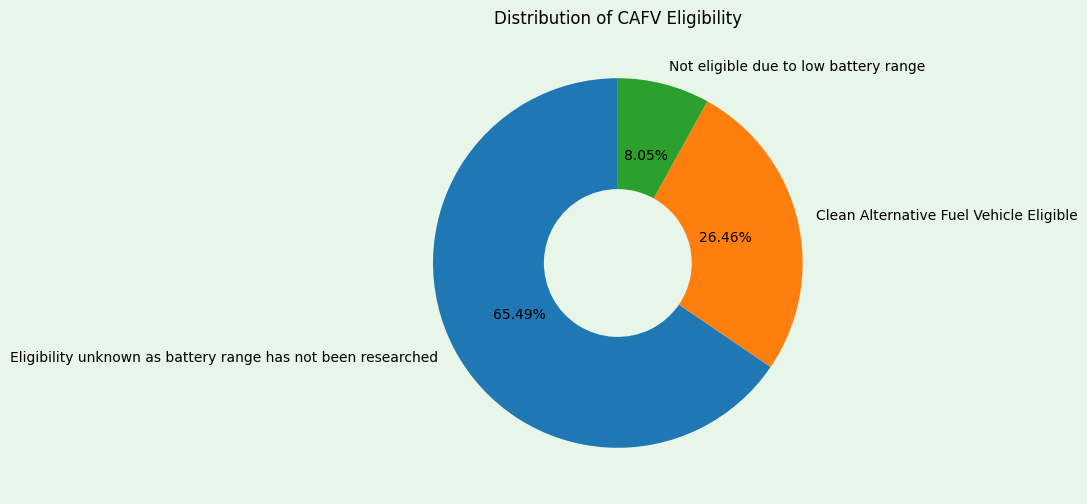

In [ ]:
plt.figure(figsize=(6, 6), facecolor= '#E8F5E9')

plt.pie(
    cafv_total,
    labels=cafv_total.index,
    autopct='%1.2f%%',
    startangle=90,
    wedgeprops= {'width': 0.6}
)

plt.title('Distribution of CAFV Eligibility')
plt.show()

**Key Findings:**
- Unknown eligibility: 195,748 records (65.49%) fall into the category where battery range has not been researched. This is the largest category in the dataset.
- CAFV eligible: 79,099 records (26.46%) are classified as eligible under the dataset's CAFV criteria.
- Not eligible: 24,069 records (8.05%) are classified as ineligible due to low battery range.
- Overall finding: Approximately two-thirds of the records have unknown CAFV eligibility, while just over one-quarter are classified as eligible.

In [ ]:
utility_total = df_WA['Electric Utility'].value_counts()
utility_percentage = (df_WA['Electric Utility'].value_counts(normalize= True)*100).round(2)
utility_summary = pd.DataFrame({'Count': utility_total, 'Percentage': utility_percentage}).head(10)
print(utility_summary)

                                                     Count  Percentage
Electric Utility                                                      
PUGET SOUND ENERGY INC||CITY OF TACOMA - (WA)       103988       34.79
PUGET SOUND ENERGY INC                               63791       21.34
CITY OF SEATTLE - (WA)|CITY OF TACOMA - (WA)         48888       16.36
BONNEVILLE POWER ADMINISTRATION||PUD NO 1 OF CL...   18318        6.13
BONNEVILLE POWER ADMINISTRATION||CITY OF TACOMA...   13964        4.67
PUGET SOUND ENERGY INC||PUD NO 1 OF WHATCOM COUNTY    7120        2.38
BONNEVILLE POWER ADMINISTRATION||AVISTA CORP||I...    5515        1.84
BONNEVILLE POWER ADMINISTRATION||PUD 1 OF SNOHO...    2959        0.99
PACIFICORP                                            2773        0.93
BONNEVILLE POWER ADMINISTRATION||PUD NO 1 OF BE...    2684         0.9


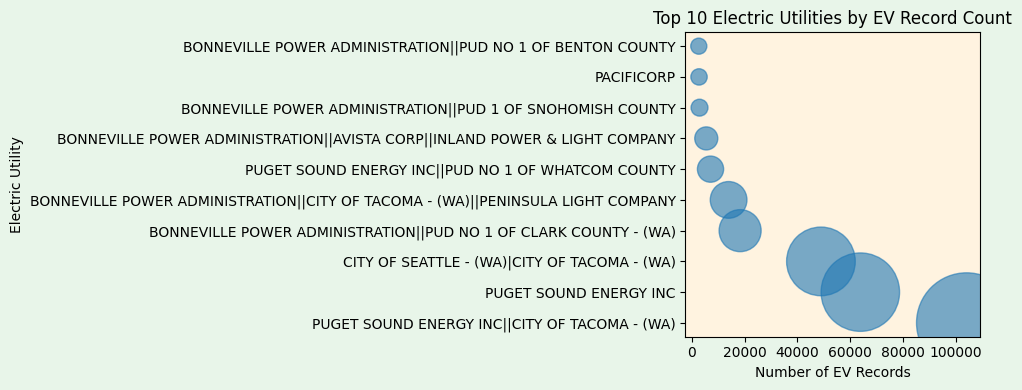

In [ ]:
plt.figure(figsize=(10,4), facecolor= '#E8F5E9')
plt.gca().set_facecolor('#FFF3E0')
utility_top10 = utility_total.head(10)
plt.scatter(
    x=utility_top10.values,
    y=utility_top10.index,
    s=utility_top10.values / 20,  # Bubble size
    alpha=0.6
)

plt.title('Top 10 Electric Utilities by EV Record Count')
plt.xlabel('Number of EV Records')
plt.ylabel('Electric Utility')
plt.tight_layout()
plt.show()

**Key Findings:**
- Puget Sound Energy Inc. combined with City of Tacoma: The largest utility entry, with 103,988 records (34.79%).
- Puget Sound Energy Inc.: Accounts for 63,791 records (21.34%), making it the second-largest entry.
- City of Seattle and City of Tacoma combined: Represents 48,888 records (16.36%).
- Bonneville Power Administration combined with PUD No. 1 of Clark County: Accounts for 18,318 records (6.13%).
- Bonneville Power Administration combined with City of Tacoma: Represents 13,964 records (4.67%).
- Top three utility entries combined: Account for 216,667 records, or approximately 72.49% of all records.

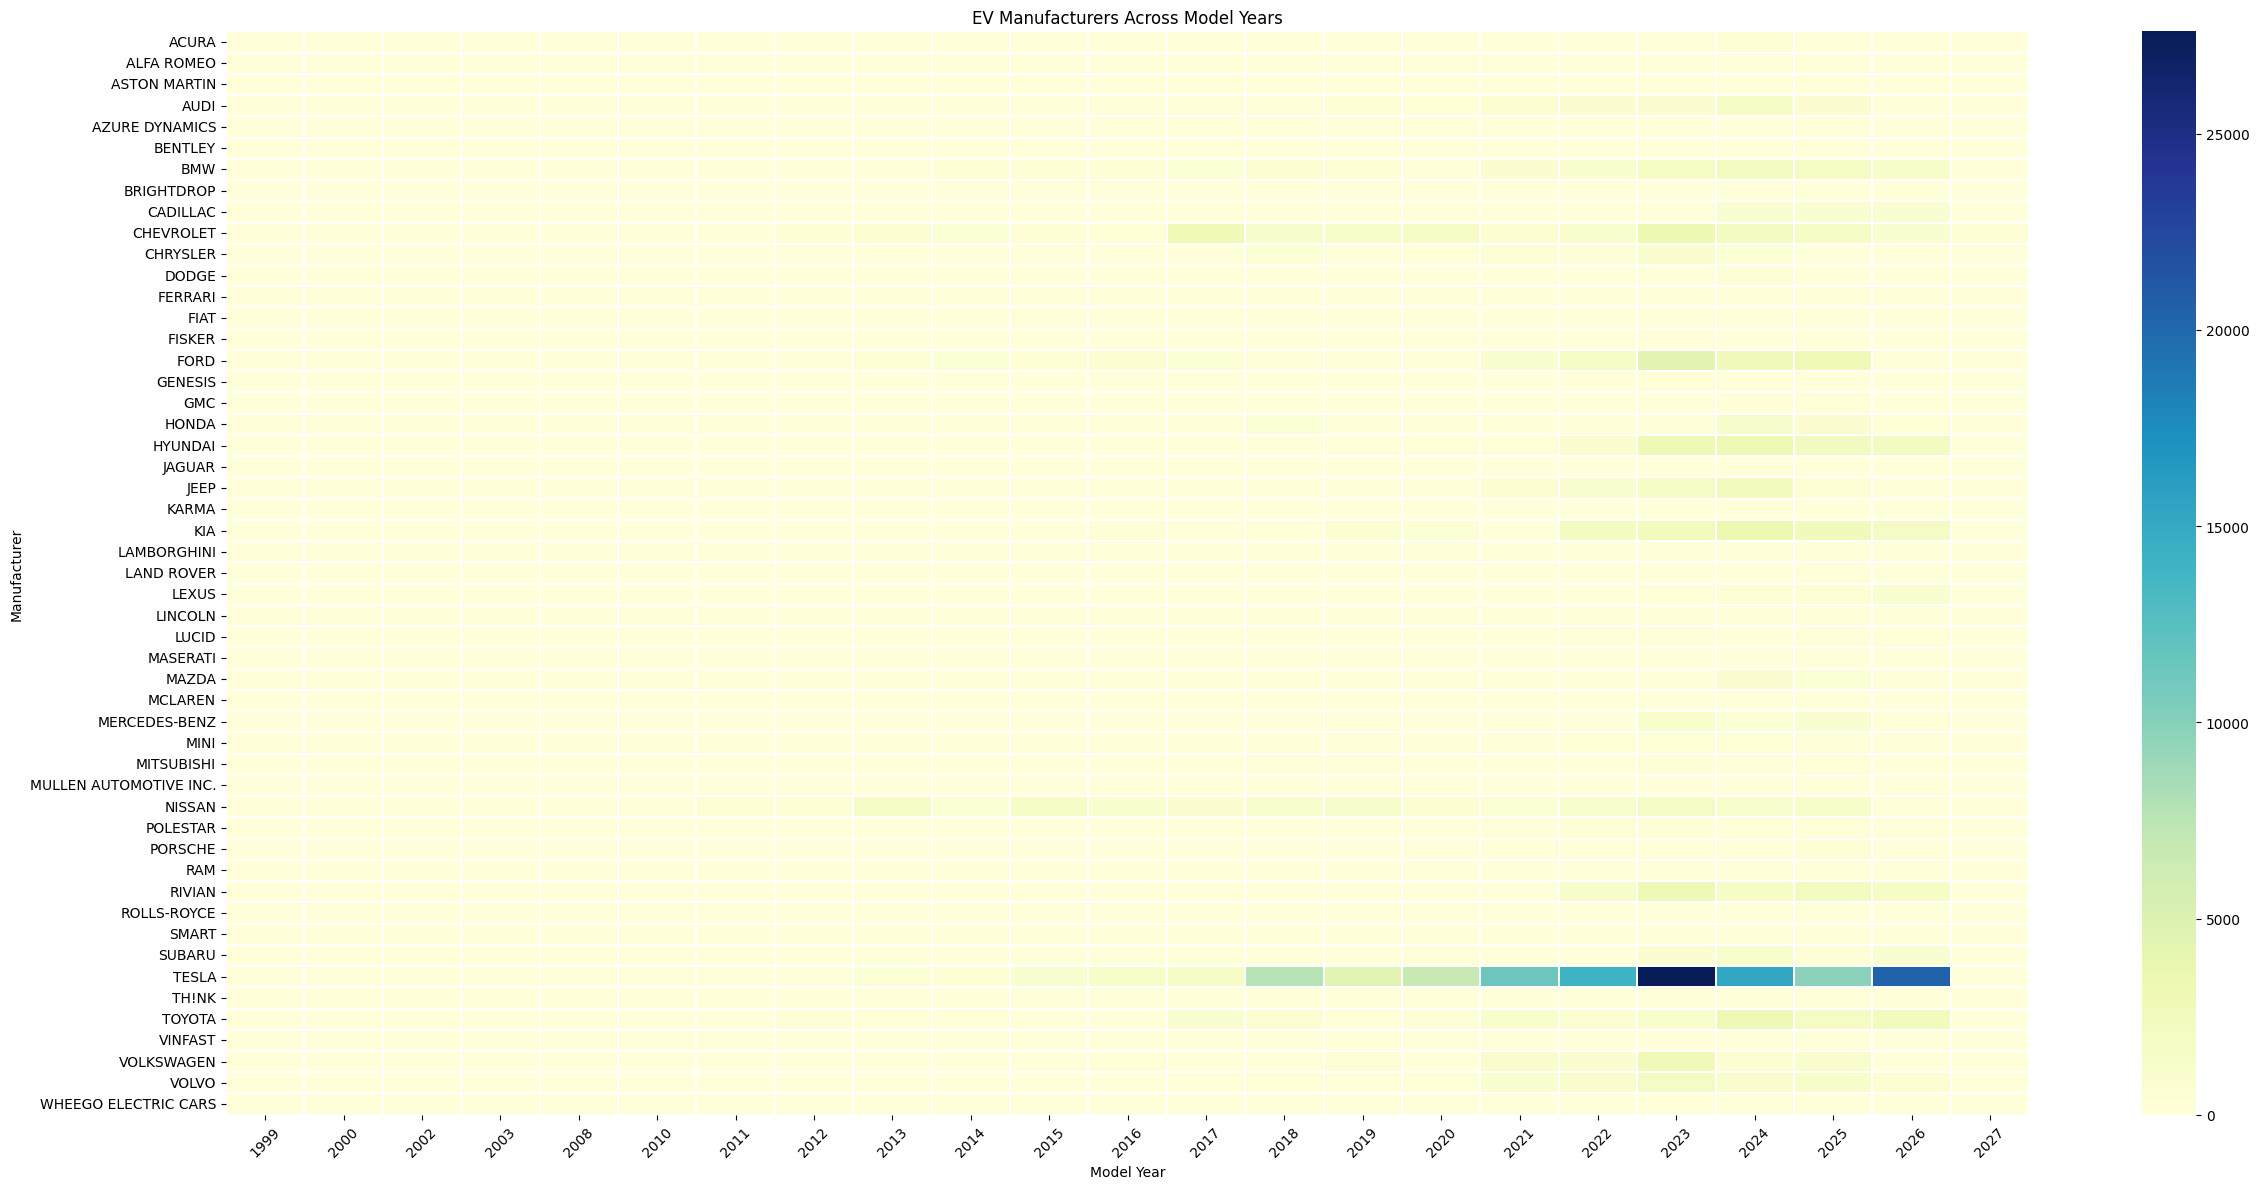

In [ ]:
ev_counts = df_WA.groupby(['Make', 'Model Year']).size().reset_index(name='Count')
heatmap_data = ev_counts.pivot(
    index='Make',
    columns='Model Year',
    values='Count'
).fillna(0)

plt.figure(figsize=(25,12))

sns.heatmap(
    heatmap_data,
    cmap='YlGnBu',
    linewidths=0.3
)

plt.title('EV Manufacturers Across Model Years')
plt.xlabel('Model Year')
plt.ylabel('Manufacturer')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


**Key Findings:**
- Tesla (2023): Tesla had a substantial representation in the 2023 model year, contributing to its highest overall count of 122,573 EV records across all model years.
- Tesla (2024): Tesla remained the leading manufacturer overall, with 122,573 records across all model years combined.
- Chevrolet: Chevrolet ranked second overall, with 20,195 EV records across all model years.
- Ford: Ford accounted for 16,075 records across all model years.
- Model Year 2023: This was the most represented model year, with 61,425 EV records across all manufacturers.

In [ ]:
# Check the GEOID column
print("Data type:", df_WA['GEOID'].dtype)
print("Missing values:", df_WA['GEOID'].isna().sum())
print("Unique GEOIDs:", df_WA['GEOID'].nunique())

# Display sample values
print(df_WA['GEOID'].head(10))

Data type: string
Missing values: 0
Unique GEOIDs: 1770
0    53033020500
1    53033022703
2    53061051932
3    53077940008
4    53033025805
5    53029971302
6    53061052207
7    53067011822
8    53077000100
9    53035091302
Name: GEOID, dtype: string


In [ ]:
population_data = pd.read_csv("washington_tract_population.csv")

print(population_data.head())
print("Rows downloaded:", len(population_data))
print(population_data.columns.tolist())

                                             NAME  Population  state  county  \
0     Census Tract 9501; Adams County; Washington        2762     53       1   
1     Census Tract 9502; Adams County; Washington        2041     53       1   
2  Census Tract 9503.01; Adams County; Washington        1780     53       1   
3  Census Tract 9503.02; Adams County; Washington        2981     53       1   
4  Census Tract 9503.03; Adams County; Washington        2399     53       1   

    tract  
0  950100  
1  950200  
2  950301  
3  950302  
4  950303  
Rows downloaded: 1784
['NAME', 'Population', 'state', 'county', 'tract']


In [ ]:
# Convert geographic codes to strings
population_data["state"] = population_data["state"].astype(str).str.zfill(2)
population_data["county"] = population_data["county"].astype(str).str.zfill(3)
population_data["tract"] = population_data["tract"].astype(str).str.zfill(6)

# Create 11-digit GEOID
population_data["GEOID"] = (
    population_data["state"]
    + population_data["county"]
    + population_data["tract"]
)

# Convert population to numeric
population_data["Population"] = pd.to_numeric(
    population_data["Population"], errors="coerce"
)

print(population_data[["NAME", "Population", "GEOID"]].head())
print("Total rows:", len(population_data))
print("Unique GEOIDs:", population_data["GEOID"].nunique())

                                             NAME  Population        GEOID
0     Census Tract 9501; Adams County; Washington        2762  53001950100
1     Census Tract 9502; Adams County; Washington        2041  53001950200
2  Census Tract 9503.01; Adams County; Washington        1780  53001950301
3  Census Tract 9503.02; Adams County; Washington        2981  53001950302
4  Census Tract 9503.03; Adams County; Washington        2399  53001950303
Total rows: 1784
Unique GEOIDs: 1784


In [ ]:
# Count EV records by census tract.
ev_by_tract = (df_WA.groupby('GEOID').size().reset_index(name= 'EV_Records'))
print(ev_by_tract.head())

         GEOID  EV_Records
0  53001950100          29
1  53001950200          16
2  53001950301          12
3  53001950302           7
4  53001950303          15


In [ ]:
# Match EV counts with population
ev_population = ev_by_tract.merge(population_data, on='GEOID', how='left', validate='one_to_one')
print("EV tracts:", len(ev_population))
print("Matched population:", ev_population['Population'].notna().sum())
print("Unmatched tracts:", ev_population['Population'].isna().sum())

EV tracts: 1770
Matched population: 1770
Unmatched tracts: 0


In [ ]:
# Calculate EV records per 1,000 residents = ((EV records)\(Population))*1000

ev_population['EV_per_1000_Residents'] = float('nan')
ev_population['EV_per_1000_Residents'] = np.where(ev_population['Population'] > 0, (ev_population['EV_Records'] / ev_population['Population']) * 1000, np.nan).round(2)
display(ev_population['EV_per_1000_Residents'])

print("Valid rates:", ev_population['EV_per_1000_Residents'].notna().sum())

print("Missing rates:", ev_population['EV_per_1000_Residents'].isna().sum())

,EV_per_1000_Residents
0,10.50
1,7.84
2,6.74
3,2.35
4,6.25
...,...
1765,3.83
1766,3.06
1767,2.95
1768,5.45


Valid rates: 1768
Missing rates: 2


In [ ]:
top_10_tracts = (ev_population.dropna(subset=['EV_per_1000_Residents']).sort_values('EV_per_1000_Residents', ascending=False).head(10))
display(top_10_tracts)

,GEOID,EV_Records,NAME,Population,state,county,tract,EV_per_1000_Residents
495,53033009300,1486,Census Tract 93; King County; Washington,3191,53,033,009300,465.68
606,53033023702,297,Census Tract 237.02; King County; Washington,1404,53,033,023702,211.54
487,53033008500,868,Census Tract 85; King County; Washington,4649,53,033,008500,186.71
662,53033026200,993,Census Tract 262; King County; Washington,5618,53,033,026200,176.75
613,53033023902,463,Census Tract 239.02; King County; Washington,2709,53,033,023902,170.91
832,53033032321,1158,Census Tract 323.21; King County; Washington,6925,53,033,032321,167.22
821,53033032224,465,Census Tract 322.24; King County; Washington,2804,53,033,032224,165.83
617,53033024200,482,Census Tract 242; King County; Washington,2928,53,033,024200,164.62
623,53033024602,570,Census Tract 246.02; King County; Washington,3485,53,033,024602,163.56
621,53033024500,806,Census Tract 245; King County; Washington,4966,53,033,024500,162.30


**Key findings:**
- All 10 top-ranked census tracts are in King County, Washington.
- Census Tract 93 has the highest ratio, with 465.68 EV records per 1,000 residents.
- Census Tract 237.02 ranks second, with 211.54 EV records per 1,000 residents.
- The remaining eight tracts range from approximately 162 to 187 EV records per 1,000 residents.
- The highest-ranked tract stands out considerably from the others, so it may be worth investigating further.

In [ ]:
bottom_10_tracts = (ev_population.dropna(subset=['EV_per_1000_Residents']).sort_values('EV_per_1000_Residents', ascending=True).head(10))
display(bottom_10_tracts)

,GEOID,EV_Records,NAME,Population,state,county,tract,EV_per_1000_Residents
431,53033005304,2,Census Tract 53.04; King County; Washington,3425,53,033,005304,0.58
1734,53077001504,2,Census Tract 15.04; Yakima County; Washington,2557,53,077,001504,0.78
430,53033005303,5,Census Tract 53.03; King County; Washington,4203,53,033,005303,1.19
1720,53077000600,10,Census Tract 6; Yakima County; Washington,6170,53,077,000600,1.62
434,53033005307,5,Census Tract 53.07; King County; Washington,3068,53,033,005307,1.63
1744,53077002004,7,Census Tract 20.04; Yakima County; Washington,3668,53,077,002004,1.91
16,53005010204,6,Census Tract 102.04; Benton County; Washington,3013,53,005,010204,1.99
305,53025011403,9,Census Tract 114.03; Grant County; Washington,4468,53,025,011403,2.01
1701,53075000100,11,Census Tract 1; Whitman County; Washington,5439,53,075,000100,2.02
1764,53077940002,9,Census Tract 9400.02; Yakima County; Washington,4407,53,077,940002,2.04


**Key findings:**
- Lowest ratio: Census Tract 53.04 in King County, with 0.58 EV records per 1,000 residents.
- Second lowest: Census Tract 15.04 in Yakima County, with 0.78 per 1,000 residents.
- The bottom 10 tracts have ratios ranging from approximately 0.58 to 2.04 EV records per 1,000 residents.
- These tracts are located in King, Yakima, Benton, Grant, and Whitman counties.
- King County appears in both the top 10 and bottom 10, showing that EV-record density varies considerably between census tracts within the same county.

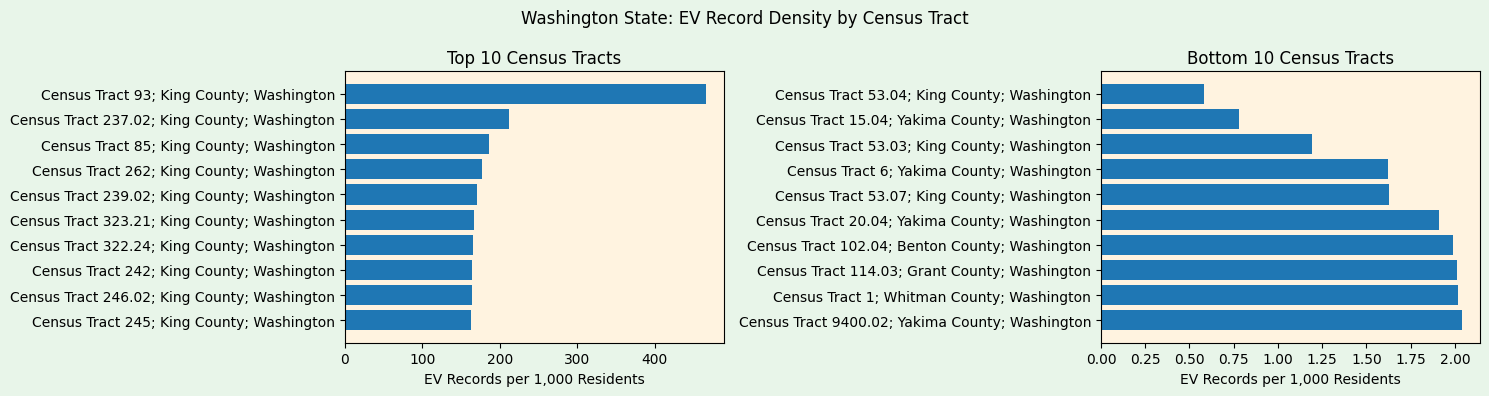

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
fig.patch.set_facecolor('#E8F5E9')
axes[0].set_facecolor('#FFF3E0')
axes[1].set_facecolor('#FFF3E0')
# Top 10 Census Tracts
axes[0].barh(top_10_tracts['NAME'], top_10_tracts['EV_per_1000_Residents'])
axes[0].set_title('Top 10 Census Tracts')
axes[0].set_xlabel('EV Records per 1,000 Residents')
axes[0].invert_yaxis()

# Bottom 10 Census Tracts
axes[1].barh(bottom_10_tracts['NAME'], bottom_10_tracts['EV_per_1000_Residents'])
axes[1].set_title('Bottom 10 Census Tracts')
axes[1].set_xlabel('EV Records per 1,000 Residents')
axes[1].invert_yaxis()

fig.suptitle('Washington State: EV Record Density by Census Tract')

plt.tight_layout()
plt.show()

#**Insights:**
**1.Manufacturer representation**:

**Tesla** was the most represented manufacturer, with **122,573** records, followed by **Chevrolet** with **20,195** and **Ford** with **16,075**. This shows that **Tesla accounts for a substantially larger share** of the recorded EV population than other manufacturers.

**2. Model-year distribution:**

Model year **2023** had the highest representation in the dataset, with **61,425** EV records, followed by **2024** with **49,273** and **2025** with **36,938**. This indicates that 2023-model-year EVs are the most represented in the available Washington State dataset. These figures reflect **Recorded vehicles by model year** rather than total manufacturing output, annual sales, or registration trends.

**3. Electric range comparison:**

Among records with positive reported electric ranges, **BEVs had an average range of 200.46 miles** and a **median of 215 miles**. **PHEVs had an average of 32.29 miles** and a **median of 32 miles**. This demonstrates the substantial difference in reported electric-only range between the two vehicle types in the analyzed subset.

**4. Geographic distribution:**

**King County** had the highest number of recorded EVs, with **144,257** records, followed by **Snohomish County** with **37,818** and **Pierce County** with **25,042**. **Seattle** was the **leading city, with 45,469 records**, followed by **Bellevue with 14,383**.

**5. Manufacturer representation across model years:**

The **heatmap showed how manufacturer record counts varied across model years**. Tesla's high overall representation was a prominent feature of the dataset. Individual manufacturer–model-year combinations can be examined to identify where each manufacturer's records are concentrated.

**6. BEV and PHEV composition:**

**BEVs** accounted for **241,125** records **(80.67%)**, while **PHEVs** accounted for **57,791** records **(19.33%)**. Therefore, BEVs made up approximately four-fifths of the recorded EV population.

**7. CAFV eligibility:**

A total of 195,748 records (65.49%) had unknown CAFV eligibility, **79,099 (26.46%) were classified as eligible**, and **24,069 (8.05%) were classified as not eligible** due to low battery range. The large unknown category highlights a limitation in the available eligibility and battery-range information.

**8. Electric utility entries:**

**The largest** recorded utility entry, **Puget Sound Energy Inc. combined with City of Tacoma**, contained **103,988** records **(34.79%)**. The next two entries had 63,791 (21.34%) and 48,888 (16.36%) records, respectively. These figures describe the utility entries as recorded in the dataset, including entries that combine multiple providers.

**9. Census Tract-Level EV Distribution Analysis**

The analysis compared EV record counts with **2024 ACS five-year population estimates** and found substantial variation in EV-record density across Washington State. All **10 highest-ranking census tracts were in** ***"King County"*, led by Census Tract 93 at 465.68 EV records per 1,000 residents. The 10 lowest-ranking tracts ranged from 0.58 to 2.04 records per 1,000 residents across** ***"King, Yakima, Benton, Grant, and Whitman counties".***
These findings highlight local differences that county-level totals may overlook. However, the ratios indicate EV-record density, not actual EV ownership or adoption rates.

**Limitation:**

 The dataset contains vehicle model years rather than transaction or registration dates. Therefore, the analysis describes the EV records represented in the dataset and does not measure annual sales, registration growth, or total vehicle manufacturing output. Electric range values of zero were also treated as unavailable or unresearched values rather than actual driving ranges.

#**Final conclusion:**
Overall, this project demonstrates how Python-based data cleaning, exploratory data analysis, and visualization can be used to investigate the composition and distribution of recorded electric vehicles in Washington State.

The analysis found that Tesla was the most represented manufacturer, BEVs formed the majority of records, and King County had the highest geographic concentration of recorded EVs. The electric-range comparison also showed a substantial difference between BEVs and PHEVs among vehicles with positive reported ranges.I also found differences in electric range, model years, and EV distribution across locations.

The findings provide a useful overview of manufacturer representation, model-year patterns, geographic distribution, vehicle types, CAFV eligibility, and recorded utility associations. However, the results should be interpreted in light of the dataset's limitations, particularly unknown eligibility, zero electric-range values, and the absence of transaction dates.

I compared EV manufacturers, vehicle types, and locations to understand how the recorded vehicle counts differ. The results show clear differences between these groups, but I would need more information to understand the exact reasons behind these patterns.

Machine learning could help me predict electric range based on details such as manufacturer, model year, and vehicle type. However, because my dataset does not contain registration dates or sales dates, I cannot use it alone to predict future EV population growth.

Based on my findings, I recommend improving missing data, examining areas where charging infrastructure may be needed, and studying EV distribution at the local level. More information about charging stations and population would help me make better recommendations.

**Data studio Dashboard link**: https://datastudio.google.com/reporting/95f747eb-76b2-4dcd-a287-9a769aa1545a/page/dEUCG

#**Dashboard**

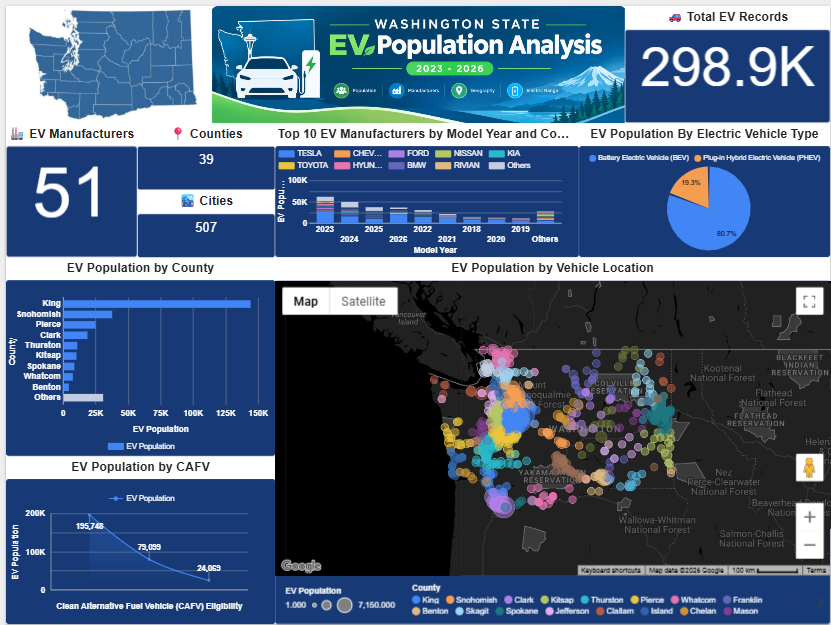

##**Thank You**